# KGS · Notebook 2 — Chỉ số giá thị trường hedonic theo tuần

Chỉ số giá trả lời câu hỏi: **"cùng một căn nhà như thế, tuần này đắt hơn hay rẻ hơn tuần gốc bao nhiêu?"**. Notebook này dựng lại chỉ số từng bước, chứng minh vì sao phải dùng phương pháp **hedonic** thay vì lấy trung vị giá mỗi tuần, rồi chỉ ra chỉ số được **tích hợp vào hệ thống** như thế nào.

| Bước | Nội dung | Tệp tương ứng trong đồ án |
|---|---|---|
| 0–1 | Cài đặt, nạp và làm sạch dữ liệu (giống notebook 1) | `training/prepare_data.py` |
| 2 | Gom tin theo tuần, chọn tuần đủ mẫu | `training/build_index.py` |
| 3 | Chỉ số ngây thơ: trung vị giá/m² mỗi tuần | `build_index.py` · `naive_median_index()` |
| 4 | Chứng minh "thay đổi cơ cấu" làm sai chỉ số ngây thơ | — |
| 5 | Dựng ma trận hồi quy hedonic | `build_index.py` · `weekly_hedonic_index()` |
| 6 | Ước lượng Ridge, rút chỉ số tuần | như trên |
| 7 | So sánh hedonic với trung vị thô | `build_index.py` · `describe()` |
| 8 | Chỉ số riêng cho 20 quận | `build_index.py` · `main()` |
| 9 | Dự báo một tuần tới và kiểm tra lùi | `app/price_index.py` · `forecast()` |
| 10 | Lưu `price_index.json` | `models/price_index.json` |
| 11 | Phục vụ và tích hợp: luồng từ người dùng | `app/main.py`, `ValuationService.cs`, `MarketTrendCard.tsx`, `chi-so-gia.tsx` |

**Thời gian chạy trên Colab:** khoảng 5–10 phút. Nếu đã chạy notebook 1 trong cùng phiên Colab thì dữ liệu đã nằm sẵn trong `kgs_data/`, không phải tải lại.

**Kết quả kỳ vọng** (chỉ số đang phục vụ, dựng 06/09/2026): 17 tuần; chỉ số hedonic dao động **2,36 điểm/tuần**, trung vị thô **4,23 điểm/tuần** (nhiễu gấp 1,79 lần); hai đường lệch trung bình 2,21 điểm, lớn nhất 4,81 điểm.

## Bước 0 — Cài đặt

In [ ]:
%pip install -q fastapi httpx

In [2]:
import os, json, time, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import sparse
from sklearn.linear_model import Ridge
from sklearn.preprocessing import OneHotEncoder

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.width", 160)
plt.rcParams["figure.dpi"] = 110

N_SHARDS = 3
DATA_DIR = Path(os.environ.get("KGS_DATA_DIR", "kgs_data"))
OUT_DIR = Path("kgs_models")
DATA_DIR.mkdir(parents=True, exist_ok=True)
OUT_DIR.mkdir(parents=True, exist_ok=True)

## Bước 1 — Nạp và làm sạch dữ liệu

Dùng **đúng** bộ dữ liệu và quy trình làm sạch của mô hình định giá (notebook 1, bước 1–3): cùng 637.598 tin rao bán. Chỉ số và mô hình định giá dùng chung hàm chuẩn hoá địa danh và hàm dựng đặc trưng.

In [3]:
# ==== Chuẩn hoá tên hành chính — chép từ ml-service/app/normalize.py ====
import re, unicodedata

_PREFIXES = ["thanh pho", "quan", "huyen", "thi xa", "thi tran", "phuong", "xa",
             "tp", "tx", "tt", "q", "h", "p"]
_MULTISPACE = re.compile(r"\s+")
_NON_ALNUM = re.compile(r"[^a-z0-9\s]")
_PROVINCE_ALIASES = {"hcm": "ho chi minh", "tphcm": "ho chi minh", "sai gon": "ho chi minh",
                     "hn": "ha noi", "dn": "da nang", "brvt": "ba ria vung tau"}

def strip_accents(text):
    """Bỏ dấu tiếng Việt bằng chuẩn hoá Unicode NFD; 'đ' phải thay tay."""
    if not text:
        return ""
    decomposed = unicodedata.normalize("NFD", text)
    stripped = "".join(c for c in decomposed if unicodedata.category(c) != "Mn")
    return unicodedata.normalize("NFC", stripped).replace("đ", "d").replace("Đ", "D")

def norm_key(value):
    """Đưa một địa danh về dạng khoá: chữ thường, không dấu, không tiền tố hành chính."""
    if not value:
        return ""
    text = strip_accents(str(value)).lower()
    text = _NON_ALNUM.sub(" ", text)
    text = _MULTISPACE.sub(" ", text).strip()
    changed = True
    while changed:                      # cắt tiền tố lặp lại: "tp thu duc" -> "thu duc"
        changed = False
        for prefix in _PREFIXES:
            if text == prefix:
                return ""
            if text.startswith(prefix + " "):
                text = text[len(prefix) + 1:].strip()
                changed = True
                break
    return text

def norm_province(value):
    key = norm_key(value)
    if key.startswith("tinh "):         # "Tỉnh Khánh Hòa" -> "khanh hoa"
        key = key[len("tinh "):].strip()
    return _PROVINCE_ALIASES.get(key, key)

def norm_district(value):
    return norm_key(value)

def norm_ward(value):
    return norm_key(value)

In [4]:
# ==== Đặc trưng — chép từ ml-service/app/features.py và app/timeparse.py ====
from dataclasses import dataclass

def parse_published(values):
    """Đọc thời gian đăng. format='ISO8601' đọc được cả dòng có và không có micro-giây."""
    return pd.to_datetime(values, format="ISO8601", utc=True, errors="coerce")

CATEGORICAL = ["property_type", "province", "district", "ward", "house_direction"]
NUMERIC = ["area", "log_area", "bedroom_count", "bathroom_count", "floor_count",
           "frontage_width", "house_depth", "road_width", "area_per_bedroom", "published_month"]
FEATURES = CATEGORICAL + NUMERIC

@dataclass(frozen=True)
class Bounds:
    min_price: float = 100_000_000          # 100 triệu
    max_price: float = 200_000_000_000      # 200 tỷ
    min_area: float = 10.0
    max_area: float = 2_000.0
    min_price_per_m2: float = 1_000_000     # 1 triệu/m²
    max_price_per_m2: float = 800_000_000   # 800 triệu/m²

DEFAULT_BOUNDS = Bounds()

def clean(df, bounds=DEFAULT_BOUNDS):
    """Lọc rác: giá, diện tích, giá mỗi m², thiếu tỉnh/quận."""
    price = pd.to_numeric(df["price"], errors="coerce")
    area = pd.to_numeric(df["area"], errors="coerce")
    with np.errstate(divide="ignore", invalid="ignore"):
        ppm2 = price / area
    keep = (price.between(bounds.min_price, bounds.max_price)
            & area.between(bounds.min_area, bounds.max_area)
            & ppm2.between(bounds.min_price_per_m2, bounds.max_price_per_m2)
            & df["province"].notna() & df["district"].notna())
    return df.loc[keep].copy()

def build_features(df):
    """Dựng 15 đặc trưng. Hàm này dùng chung cho lúc huấn luyện VÀ lúc phục vụ dự đoán."""
    out = pd.DataFrame(index=df.index)
    out["property_type"] = df["property_type"].fillna("").astype(str).str.strip().str.lower()
    out["province"] = df["province"].map(norm_province)
    out["district"] = df["district"].map(norm_district)
    out["ward"] = df["ward"].map(norm_ward)
    out["house_direction"] = (df.get("house_direction", pd.Series(index=df.index, dtype=object))
                              .fillna("").astype(str).str.strip().str.lower())
    area = pd.to_numeric(df["area"], errors="coerce")
    out["area"] = area
    out["log_area"] = np.log1p(area.clip(lower=0))
    for col in ["bedroom_count", "bathroom_count", "floor_count",
                "frontage_width", "house_depth", "road_width"]:
        out[col] = pd.to_numeric(df.get(col), errors="coerce")
    with np.errstate(divide="ignore", invalid="ignore"):
        out["area_per_bedroom"] = area / out["bedroom_count"].replace(0, np.nan)
    published = parse_published(df.get("published_at"))
    out["published_month"] = ((published.dt.year - 2020) * 12 + published.dt.month).astype("float64")
    return out

def to_categorical(df, categories=None):
    """Ép cột phân loại về 'category'. Lúc phục vụ PHẢI dùng lại đúng tập hạng mục lúc train."""
    out = df.copy()
    for col in CATEGORICAL:
        if categories is not None:
            out[col] = pd.Categorical(out[col], categories=categories[col])
        else:
            out[col] = out[col].astype("category")
    return out

def category_map(df):
    return {col: list(df[col].cat.categories) for col in CATEGORICAL}

In [5]:
# ==== Tải dữ liệu — tương ứng ml-service/training/prepare_data.py ====
import requests

BASE_URL = "https://huggingface.co/api/datasets/tinixai/vietnam-real-estates/parquet/default/train"
COLUMN_MAP = {
    "property_type_name": "property_type", "province_name": "province",
    "district_name": "district", "ward_name": "ward", "street_name": "street",
    "project_name": "project", "house_direction": "house_direction",
    "balcony_direction": "balcony_direction", "price": "price", "area": "area",
    "floor_count": "floor_count", "frontage_width": "frontage_width",
    "house_depth": "house_depth", "road_width": "road_width",
    "bedroom_count": "bedroom_count", "bathroom_count": "bathroom_count",
    "published_at": "published_at", "name": "title",
}

def download_shard(i):
    """Tải một shard parquet về đĩa (bỏ qua nếu đã có) — chạy lại notebook không phải tải lại."""
    path = DATA_DIR / f"shard_{i}.parquet"
    if not path.exists():
        print(f"  tải shard {i} …", flush=True)
        with requests.get(f"{BASE_URL}/{i}.parquet", stream=True, timeout=120) as r:
            r.raise_for_status()
            tmp = path.with_suffix(".part")
            with open(tmp, "wb") as f:
                for chunk in r.iter_content(chunk_size=1 << 20):
                    f.write(chunk)
            tmp.rename(path)
    return path

def load_raw(n_shards):
    frames = []
    for i in range(n_shards):
        df = pd.read_parquet(download_shard(i), columns=list(COLUMN_MAP.keys()))
        frames.append(df.rename(columns=COLUMN_MAP))
        print(f"  shard {i}: {len(df):,} dòng")
    return pd.concat(frames, ignore_index=True)

def prepare(raw):
    """Làm sạch + bỏ tin trùng, đúng thứ tự của prepare_data.py."""
    df = raw.copy()
    df["province_key"] = df["province"].map(norm_province)
    df = clean(df, DEFAULT_BOUNDS)
    df = df.drop_duplicates(subset=["province", "district", "ward", "street",
                                    "area", "price", "bedroom_count"])
    return df

In [6]:
t0 = time.time()
df = prepare(load_raw(N_SHARDS))
ts = parse_published(df["published_at"])
df = df.loc[ts.notna()].copy()
ts = ts.loc[df.index]
print(f"{len(df):,} tin sau làm sạch  (báo cáo đồ án: 637.598) · {time.time() - t0:.0f} giây")
print(f"Thời gian đăng: {ts.min():%d/%m/%Y} → {ts.max():%d/%m/%Y}")

  shard 0: 350,075 dòng


  shard 1: 350,075 dòng


  shard 2: 350,075 dòng


637,598 tin sau làm sạch  (báo cáo đồ án: 637.598) · 11 giây
Thời gian đăng: 01/06/2025 → 29/09/2025


## Bước 2 — Gom tin theo tuần, chọn tuần đủ mẫu

Mỗi tin được gán vào tuần đăng (thứ Hai → Chủ nhật). Tuần có quá ít tin thì hệ số của nó chủ yếu là nhiễu, nên bị **loại và nói rõ là đã loại** — thay vì để một điểm rung lắc mạnh mà người xem tưởng là thị trường.

- Ngưỡng toàn quốc: **≥ 3.000 tin/tuần**.
- Ngưỡng cấp quận (bước 8): **≥ 150 tin/tuần**, chỉ xét quận có **≥ 4.000 tin**.

In [7]:
MIN_WEEK_SAMPLE = 3_000
MIN_WEEK_SAMPLE_DISTRICT = 150
MIN_DISTRICT_SAMPLE = 4_000

weeks = ts.dt.tz_convert(None).dt.to_period("W")
counts = weeks.value_counts().sort_index()
week_table = pd.DataFrame({"tuần bắt đầu": [w.start_time.date() for w in counts.index],
                           "số tin": counts.values,
                           "dùng cho chỉ số": np.where(counts.values >= MIN_WEEK_SAMPLE, "có", "LOẠI (ít mẫu)")})
print(f"{len(counts)} tuần có dữ liệu, {int((counts >= MIN_WEEK_SAMPLE).sum())} tuần đủ mẫu.")
week_table

19 tuần có dữ liệu, 17 tuần đủ mẫu.


,tuần bắt đầu,số tin,dùng cho chỉ số
0,2025-05-26,2270,LOẠI (ít mẫu)
1,2025-06-02,43328,có
2,2025-06-09,38161,có
3,2025-06-16,48489,có
4,2025-06-23,58530,có
5,2025-06-30,38445,có
6,2025-07-07,50473,có
7,2025-07-14,50722,có
8,2025-07-21,47374,có
9,2025-07-28,41324,có


**Đọc bảng:** tuần đầu và tuần cuối bị cắt cụt (dữ liệu bắt đầu và kết thúc giữa tuần) nên bị loại. Từ tháng 9, số tin chỉ còn khoảng **1/4** so với tháng 6–8. Đó là **dấu vết của việc thu thập dữ liệu**, không phải tín hiệu thị trường — chỉ số sẽ ghi rõ điều này.

## Bước 3 — Chỉ số ngây thơ: trung vị giá/m² mỗi tuần

Cách hiển nhiên nhất: lấy trung vị giá mỗi m² của từng tuần, chia cho tuần đầu, nhân 100. Dựng ra **để so sánh, không để dùng**.

In [8]:
def naive_median_index(df, weeks):
    ppm2 = df["price"].to_numpy(dtype="float64") / df["area"].to_numpy(dtype="float64")
    tmp = pd.DataFrame({"week": weeks.to_numpy(), "ppm2": ppm2})
    tmp = tmp[np.isfinite(tmp["ppm2"])]
    med = tmp.groupby("week")["ppm2"].agg(["median", "size"]).sort_index()
    med = med[med["size"] >= MIN_WEEK_SAMPLE]
    base = med["median"].iloc[0]
    return [{"week_start": str(w.start_time.date()), "index": round(float(m / base * 100.0), 2), "n": int(n)}
            for w, (m, n) in med[["median", "size"]].iterrows()]

df["price"] = pd.to_numeric(df["price"]); df["area"] = pd.to_numeric(df["area"])
naive = naive_median_index(df, weeks)
naive_s = pd.Series({p["week_start"]: p["index"] for p in naive})
naive_s.round(2).to_frame("chỉ số trung vị thô").T

,2025-06-02,2025-06-09,2025-06-16,2025-06-23,2025-06-30,2025-07-07,2025-07-14,2025-07-21,2025-07-28,2025-08-04,2025-08-11,2025-08-18,2025-08-25,2025-09-01,2025-09-08,2025-09-15,2025-09-22
chỉ số trung vị thô,100.0,102.49,104.36,98.56,96.59,103.52,100.88,101.22,100.34,97.58,103.27,105.81,101.28,94.55,100.31,101.75,108.02


## Bước 4 — Vì sao chỉ số ngây thơ sai: thay đổi cơ cấu (mix shift)

Tuần này ngẫu nhiên có nhiều tin ở quận đắt hơn, trung vị nhảy lên; tuần sau nhiều tin ở quận rẻ, nó rơi xuống. **Không căn nhà nào đổi giá cả** — chỉ là danh mục tin đăng đổi thành phần.

Kiểm chứng: dựng một **"chỉ số cơ cấu"** — gán cho mỗi tin *giá trung vị/m² cả kỳ của chính quận nó*, rồi lấy trung bình nhân theo tuần. Chỉ số này **giữ giá mọi quận cố định**, chỉ thay đổi khi *cơ cấu tin* thay đổi. Nếu nó đi cùng chiều với chỉ số ngây thơ, thì phần lớn biến động của chỉ số ngây thơ là do cơ cấu, không phải do giá.

Tương quan giữa biến động tuần của chỉ số thô và chỉ số cơ cấu: 0.81


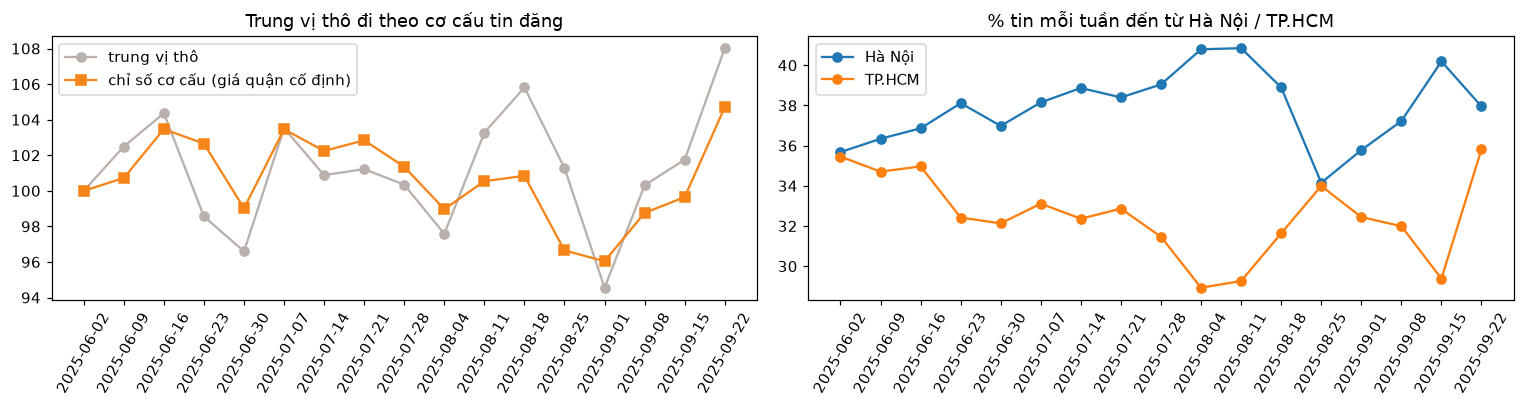

In [9]:
X_all = build_features(df)
df = df.assign(_prov=X_all["province"], _dist=X_all["district"])
ppm2 = df["price"] / df["area"]
district_level = ppm2.groupby([df["_prov"], df["_dist"]]).transform("median")   # giá quận CỐ ĐỊNH cả kỳ

good_weeks = counts[counts >= MIN_WEEK_SAMPLE].index
in_good = weeks.isin(good_weeks)
# trung bình nhân (mean của log) — trung vị của vài trăm mức giá quận sẽ nhảy bậc thang
mix = np.exp(np.log(district_level[in_good]).groupby(weeks[in_good]).mean())
mix_s = pd.Series((mix / mix.iloc[0] * 100).values, index=[str(w.start_time.date()) for w in mix.index])

share = (df.loc[in_good, "province_key"].groupby(weeks[in_good])
         .value_counts(normalize=True).unstack(fill_value=0)[["ha noi", "ho chi minh"]] * 100)

share.index = [str(w.start_time.date()) for w in share.index]
mix_s = mix_s.reindex(naive_s.index)
corr = np.corrcoef(naive_s.diff().dropna(), mix_s.diff().dropna())[0, 1]
print(f"Tương quan giữa biến động tuần của chỉ số thô và chỉ số cơ cấu: {corr:.2f}")

fig, axes = plt.subplots(1, 2, figsize=(14, 3.8))
axes[0].plot(naive_s.index, naive_s.values, marker="o", color="#BAB0AC", label="trung vị thô")
axes[0].plot(mix_s.index, mix_s.values, marker="s", color="#F58518", label="chỉ số cơ cấu (giá quận cố định)")
axes[0].set_title("Trung vị thô đi theo cơ cấu tin đăng"); axes[0].legend(); axes[0].tick_params(axis="x", rotation=60)
axes[1].plot(share.index, share["ha noi"], marker="o", label="Hà Nội")
axes[1].plot(share.index, share["ho chi minh"], marker="o", label="TP.HCM")
axes[1].set_title("% tin mỗi tuần đến từ Hà Nội / TP.HCM"); axes[1].legend(); axes[1].tick_params(axis="x", rotation=60)
plt.tight_layout(); plt.show()

**Đọc kết quả:** hệ số tương quan in ở trên đo mức biến động tuần của trung vị thô đi cùng chiều với chỉ số cơ cấu — tức phần biến động sinh ra chỉ vì *tỷ lệ tin giữa các quận* thay đổi. Phần còn lại đến từ cơ cấu **bên trong** quận (tuần này nhiều nhà mặt phố, tuần sau nhiều căn hộ nhỏ) mà chỉ số cơ cấu theo quận chưa bắt được. Hồi quy hedonic ở bước sau kiểm soát **cả hai**: vị trí lẫn diện tích, loại hình, số phòng.

## Bước 5 — Hồi quy hedonic: dựng ma trận

Phương pháp chuẩn của các cơ quan thống kê khi dựng chỉ số giá nhà (*time-dummy hedonic*):

$$\ln P_i = \alpha + \sum_k \beta_k X_{ik} + \sum_t \delta_t D_{it} + \varepsilon_i, \qquad \text{Index}_t = 100\cdot e^{\delta_t - \delta_{t_0}}$$

- **X — biến kiểm soát:** loại hình, tỉnh, quận, phường, hướng nhà (one-hot, gộp hạng mục dưới 30 tin vào nhóm "khác"); log(diện tích), phòng ngủ, phòng tắm, số tầng, mặt tiền.
- **Ô trống:** điền trung vị **kèm cờ "đã thiếu"** — vì việc không khai số tầng cũng tương quan với loại bất động sản; vứt thông tin đó đi thì mô hình quy nhầm phần biến động ấy sang biến tuần.
- **D — biến giả tuần:** mỗi tuần một cột 0/1. Cố ý **không** đưa "tháng đăng" vào X, để biến thời gian duy nhất là các biến giả tuần.
- **δ_t chính là chỉ số:** phần biến động giá còn lại **sau khi** đã trừ ảnh hưởng của vị trí, diện tích, loại hình, số phòng.

In [10]:
CONTROL_CAT = ["property_type", "province", "district", "ward", "house_direction"]
CONTROL_NUM = ["log_area", "bedroom_count", "bathroom_count", "floor_count", "frontage_width"]

def design_matrix(df, weeks, min_week):
    counts = weeks.value_counts().sort_index()
    good = counts[counts >= min_week].index
    keep = weeks.isin(good)
    df, weeks = df.loc[keep], weeks.loc[keep]
    X_raw = build_features(df)
    y = np.log(df["price"].to_numpy(dtype="float64"))

    enc_cat = OneHotEncoder(handle_unknown="ignore", min_frequency=30, sparse_output=True)
    M_cat = enc_cat.fit_transform(X_raw[CONTROL_CAT].astype(str))

    num = X_raw[CONTROL_NUM].astype("float64")
    missing_flags = num.isna().astype("float64").to_numpy()
    M_num = sparse.csr_matrix(np.hstack([num.fillna(num.median()).to_numpy(), missing_flags]))

    week_order = sorted(good)
    week_index = {w: i for i, w in enumerate(week_order)}
    M_week = sparse.csr_matrix((np.ones(len(weeks)), (np.arange(len(weeks)), weeks.map(week_index).to_numpy())),
                               shape=(len(weeks), len(week_order)))
    M = sparse.hstack([M_cat, M_num, M_week], format="csr")
    return M, y, M_cat.shape[1] + M_num.shape[1], week_order, counts, y

M, y, n_control, week_order, counts_used, _ = design_matrix(df, weeks, MIN_WEEK_SAMPLE)
print(f"Ma trận: {M.shape[0]:,} tin × {M.shape[1]:,} cột")
print(f"  {n_control:,} cột kiểm soát (one-hot vị trí, loại hình… + 5 cột số + 5 cờ thiếu)")
print(f"  {len(week_order)} cột biến giả tuần")
print(f"  mật độ khác 0: {M.nnz / (M.shape[0] * M.shape[1]) * 100:.3f}% → lưu dạng ma trận thưa")

Ma trận: 633,385 tin × 1,520 cột
  1,503 cột kiểm soát (one-hot vị trí, loại hình… + 5 cột số + 5 cờ thiếu)
  17 cột biến giả tuần
  mật độ khác 0: 0.868% → lưu dạng ma trận thưa


## Bước 6 — Ước lượng và rút chỉ số tuần

Dùng **Ridge với α = 1**: cần một chút phạt để ma trận thưa gần cộng tuyến (hàng nghìn phường) không làm hệ số nổ tung, nhưng phạt mạnh sẽ kéo chính các hệ số tuần về 0 và làm chỉ số **phẳng một cách giả tạo**.

Mỗi điểm chỉ số kèm **biên sai số 95% xấp xỉ** = 1,96 × độ lệch chuẩn của log-giá / √(số tin tuần đó): tuần ít mẫu thì điểm lung lay nhiều hơn.

In [11]:
def weekly_hedonic_index(df, weeks, label, min_week=MIN_WEEK_SAMPLE, allowed_weeks=None):
    """Chép từ build_index.py: trả danh sách điểm chỉ số, hoặc None nếu < 4 tuần đủ mẫu."""
    if allowed_weeks is not None:                 # chuỗi quận: chỉ các tuần toàn quốc cũng dùng
        keep = weeks.isin(allowed_weeks)
        df, weeks = df.loc[keep], weeks.loc[keep]
    counts = weeks.value_counts().sort_index()
    if int((counts >= min_week).sum()) < 4:
        print(f"  [{label}] không đủ tuần có mẫu — bỏ qua."); return None
    M, y, n_control, week_order, counts, _ = design_matrix(df, weeks, min_week)
    model = Ridge(alpha=1.0, fit_intercept=True, solver="sparse_cg")
    model.fit(M, y)
    deltas = model.coef_[n_control:]
    base = deltas[0]
    return [{"week_start": str(w.start_time.date()),
             "index": round(float(np.exp(d - base) * 100.0), 2),
             "n": int(counts[w]),
             "moe_percent": round(float(1.96 * y.std() / np.sqrt(counts[w]) * 100.0), 2)}
            for w, d in zip(week_order, deltas)]

t0 = time.time()
national = weekly_hedonic_index(df, weeks, "toàn quốc")
print(f"Ước lượng xong trong {time.time() - t0:.0f} giây")
pd.DataFrame(national).set_index("week_start")

Ước lượng xong trong 26 giây


,index,n,moe_percent
week_start,,,
2025-06-02,100.00,43328,1.00
2025-06-09,101.10,38161,1.07
2025-06-16,99.92,48489,0.95
2025-06-23,100.67,58530,0.86
2025-06-30,100.05,38445,1.06
2025-07-07,101.60,50473,0.93
2025-07-14,100.96,50722,0.92
2025-07-21,100.97,47374,0.96
2025-07-28,101.44,41324,1.02


## Bước 7 — So sánh hedonic với trung vị thô

In [12]:
def describe(points):
    vals = [p["index"] for p in points]
    return {"change_points": round(vals[-1] - vals[0], 2),
            "weekly_volatility": round(float(np.std(np.diff(vals))), 2)}

st_h, st_n = describe(national), describe(naive)
hed_s = pd.Series({p["week_start"]: p["index"] for p in national})
gaps = (hed_s - naive_s.reindex(hed_s.index)).abs()
mix_gap = {"mean_points": round(float(gaps.mean()), 2), "max_points": round(float(gaps.max()), 2)}

pd.DataFrame({
    "hedonic": [st_h["weekly_volatility"], st_h["change_points"]],
    "trung vị thô": [st_n["weekly_volatility"], st_n["change_points"]],
}, index=["dao động tuần (độ lệch chuẩn của mức thay đổi, điểm)", "thay đổi đầu → cuối (điểm)"])

,hedonic,trung vị thô
"dao động tuần (độ lệch chuẩn của mức thay đổi, điểm)",2.36,4.23
thay đổi đầu → cuối (điểm),6.02,8.02


Trung vị thô nhiễu gấp 1.79 lần hedonic.
Hai đường lệch nhau trung bình 2.21 điểm, lớn nhất 4.81 điểm (tuần 2025-08-25) — toàn bộ phần lệch là biến động do đổi cơ cấu tin đăng.


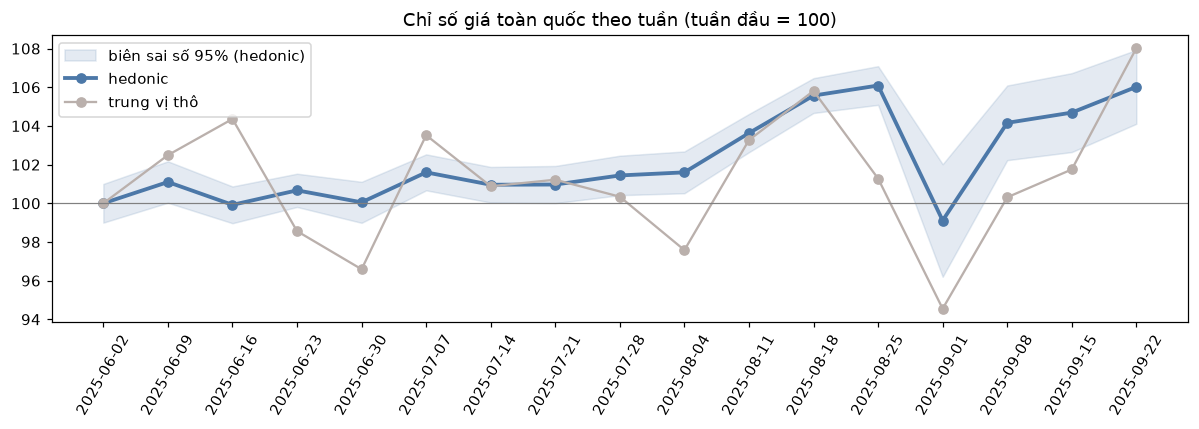

In [13]:
print(f"Trung vị thô nhiễu gấp {st_n['weekly_volatility'] / st_h['weekly_volatility']:.2f} lần hedonic.")
print(f"Hai đường lệch nhau trung bình {mix_gap['mean_points']} điểm, lớn nhất {mix_gap['max_points']} điểm "
      f"(tuần {gaps.idxmax()}) — toàn bộ phần lệch là biến động do đổi cơ cấu tin đăng.")

moe = pd.Series({p["week_start"]: p["moe_percent"] for p in national})
plt.figure(figsize=(11, 4))
plt.fill_between(hed_s.index, hed_s - moe, hed_s + moe, color="#4C78A8", alpha=0.15, label="biên sai số 95% (hedonic)")
plt.plot(hed_s.index, hed_s.values, marker="o", color="#4C78A8", lw=2.5, label="hedonic")
plt.plot(naive_s.index, naive_s.values, marker="o", color="#BAB0AC", label="trung vị thô")
plt.axhline(100, color="gray", lw=0.8)
plt.title("Chỉ số giá toàn quốc theo tuần (tuần đầu = 100)")
plt.xticks(rotation=60); plt.legend(); plt.tight_layout(); plt.show()

## Bước 8 — Chỉ số riêng cho từng quận

Chỉ dựng cho quận có ≥ 4.000 tin (lấy 20 quận lớn nhất), với ngưỡng 150 tin/tuần. Ngưỡng thấp hơn toàn quốc là hợp lý chứ không phải nới tay: trong một quận, hồi quy chỉ ước lượng vài chục hệ số thay vì vài trăm, nên cùng mức tin cậy cần ít mẫu hơn. (Lần chạy đầu áp ngưỡng toàn quốc xuống cấp quận thì chỉ dựng được **một** quận với 4 tuần.)

**Chuỗi quận chỉ dùng những tuần mà chuỗi toàn quốc cũng dùng.** Thiếu quy tắc này, một quận lớn như Thủ Đức vượt ngưỡng 150 tin ngay ở tuần đầu bị cắt cụt (26/05 — dữ liệu chỉ có tin của ngày Chủ nhật 01/06). Tuần đó trở thành tuần gốc = 100, và chỉ số nhảy +22 điểm ngay tuần sau: chuỗi báo "Thủ Đức tăng 28 điểm" trong khi phần lớn là do tuần gốc. Áp quy tắc thì Thủ Đức tăng **4,7 điểm**, và mọi chuỗi có chung tuần gốc nên so được với nhau. Lỗi này được phát hiện khi dựng lại chỉ số trong chính notebook này, và đã sửa trong `build_index.py`.

In [14]:
sizes = df.groupby(["_prov", "_dist"]).size().sort_values(ascending=False)
big = sizes[sizes >= MIN_DISTRICT_SAMPLE]
print(f"{len(big)} quận có từ {MIN_DISTRICT_SAMPLE:,} tin trở lên; dựng chỉ số cho 20 quận lớn nhất.\n")

# Chuỗi quận dùng CHUNG bộ tuần với toàn quốc: cùng tuần gốc 02/06, không tuần cắt cụt nào.
national_weeks = pd.PeriodIndex([p["week_start"] for p in national], freq="W")
districts = []
t0 = time.time()
for (prov, dist), n in big.head(20).items():
    sub = df[(df["_prov"] == prov) & (df["_dist"] == dist)]
    pts = weekly_hedonic_index(sub, weeks.loc[sub.index], f"{prov}/{dist}",
                               min_week=MIN_WEEK_SAMPLE_DISTRICT, allowed_weeks=national_weeks)
    if pts is None:
        continue
    districts.append({"province": prov, "district": dist, "n": int(n), "points": pts, **describe(pts)})
print(f"Dựng {len(districts)} chuỗi quận trong {time.time() - t0:.0f} giây")
dist_table = pd.DataFrame([{k: d[k] for k in ["province", "district", "n", "change_points", "weekly_volatility"]}
                           | {"số tuần": len(d["points"])} for d in districts])
dist_table.sort_values("change_points", ascending=False)

40 quận có từ 4,000 tin trở lên; dựng chỉ số cho 20 quận lớn nhất.



Dựng 20 chuỗi quận trong 11 giây


,province,district,n,change_points,weekly_volatility,số tuần
16,ha noi,ba dinh,12176,11.98,2.88,16
14,ha noi,hai ba trung,12962,11.76,3.74,16
5,ha noi,dong da,19768,11.58,3.86,17
6,ha noi,hoang mai,18647,10.87,2.15,17
3,ha noi,nam tu liem,21413,10.20,1.80,17
1,ha noi,cau giay,24280,9.57,2.68,17
17,ha noi,tay ho,11523,7.73,2.47,16
18,ha noi,bac tu liem,11422,7.44,2.60,16
7,ho chi minh,go vap,17297,7.13,2.30,16
10,ha noi,thanh xuan,16823,6.24,1.51,16


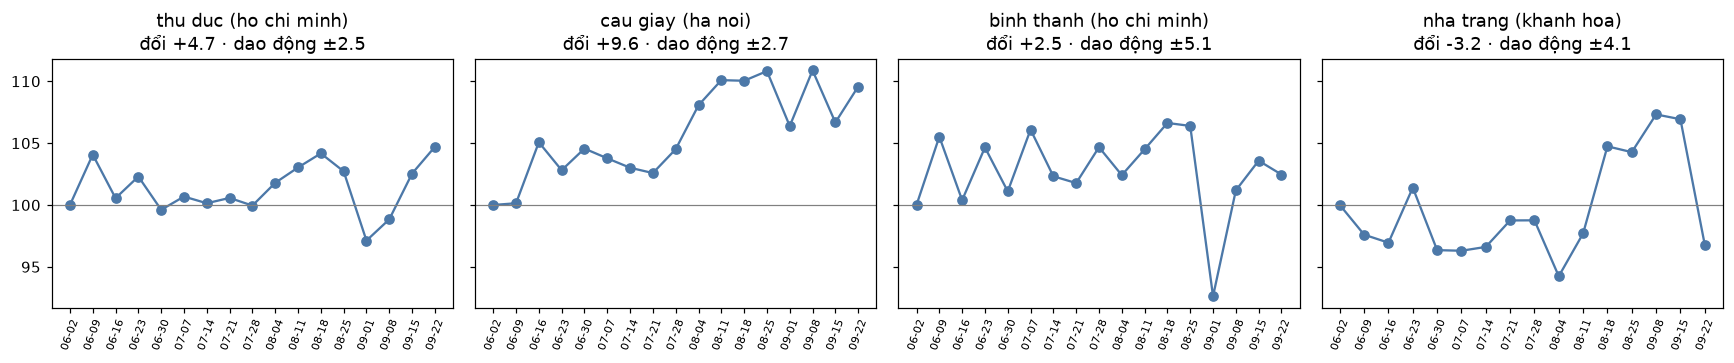

In [15]:
pick = ["thu duc", "cau giay", "binh thanh", "nha trang"]
fig, axes = plt.subplots(1, len(pick), figsize=(16, 3.4), sharey=True)
for ax, name in zip(axes, pick):
    d = next(x for x in districts if x["district"] == name)
    s = pd.Series({p["week_start"][5:]: p["index"] for p in d["points"]})
    ax.plot(s.index, s.values, marker="o", color="#4C78A8"); ax.axhline(100, color="gray", lw=0.8)
    ax.set_title(f"{d['district']} ({d['province']})\nđổi {d['change_points']:+.1f} · dao động ±{d['weekly_volatility']:.1f}")
    ax.tick_params(axis="x", rotation=70, labelsize=7)
plt.tight_layout(); plt.show()

## Bước 9 — Dự báo một tuần tới, và nói thật khi chưa đủ dữ liệu

17 điểm tuần là **quá ít** để dự báo tử tế. Phần dự báo vẫn được dựng nhưng theo cách trung thực:

1. Ba phương pháp đơn giản nhất: **ngây thơ** (tuần tới = tuần này), **xu hướng tuyến tính** (nối điểm đầu – điểm cuối), **làm mượt hàm mũ** (α = 0,4).
2. **Kiểm tra lùi** trên 4 tuần cuối: mỗi lần chỉ dùng dữ liệu tới tuần trước để đoán tuần sau, đo sai số phần trăm.
3. Chọn phương pháp sai ít nhất. Chỉ gắn nhãn **"đáng tin"** khi sai số kiểm tra lùi < 2%; nếu không, trả `reliable: false` để giao diện nói thẳng là chưa dự báo được.

Mô hình ngây thơ thắng là một kết quả **hợp lệ và đáng báo cáo**, không phải thất bại cần giấu.

In [16]:
def _naive(h):  return h[-1]
def _drift(h):  return h[-1] + (h[-1] - h[0]) / (len(h) - 1) if len(h) > 1 else h[-1]
def _ses(h, alpha=0.4):
    level = h[0]
    for v in h[1:]:
        level = alpha * v + (1 - alpha) * level
    return level
METHODS = [("Ngây thơ (tuần tới = tuần này)", _naive), ("Xu hướng tuyến tính", _drift), ("Làm mượt hàm mũ", _ses)]
HOLDOUT, MIN_POINTS = 4, 10

def backtest(values, fn, holdout=HOLDOUT):
    errs = [abs(fn(values[:i]) - values[i]) / values[i] * 100 for i in range(len(values) - holdout, len(values))]
    return float(np.mean(errs))

def forecast(points):
    values = [p["index"] for p in points]
    if len(values) < MIN_POINTS:
        return None
    scored = sorted(((name, fn, backtest(values, fn)) for name, fn in METHODS), key=lambda x: x[2])
    name, fn, mape = scored[0]
    nxt = fn(values)
    return {"method": name, "next_index": round(nxt, 2),
            "change_percent": round((nxt - values[-1]) / values[-1] * 100, 2),
            "backtest_mape": round(mape, 3), "reliable": bool(mape < 2.0),
            "note": "Chọn theo kiểm tra lùi 4 tuần cuối."}

vals = [p["index"] for p in national]
display(pd.DataFrame([{"phương pháp": n, "sai số kiểm tra lùi (%)": round(backtest(vals, f), 3),
                       "dự báo tuần tới": round(f(vals), 2)} for n, f in METHODS]))
print("Kết quả trả cho giao diện:", json.dumps(forecast(national), ensure_ascii=False, indent=1))

,phương pháp,sai số kiểm tra lùi (%),dự báo tuần tới
0,Ngây thơ (tuần tới = tuần này),3.413,106.02
1,Xu hướng tuyến tính,3.413,106.40
2,Làm mượt hàm mũ,2.723,104.65


Kết quả trả cho giao diện: {
 "method": "Làm mượt hàm mũ",
 "next_index": 104.65,
 "change_percent": -1.29,
 "backtest_mape": 2.723,
 "reliable": false,
 "note": "Chọn theo kiểm tra lùi 4 tuần cuối."
}


## Bước 10 — Lưu `price_index.json`

Toàn bộ chỉ số được **tính trước** (offline) và lưu thành một tệp JSON: chuỗi toàn quốc, chuỗi trung vị thô để đối chiếu, 20 chuỗi quận, khoảng cách do cơ cấu, và các lưu ý. Dịch vụ chỉ việc nạp tệp này lúc khởi động — mỗi yêu cầu chỉ là tra cứu, phản hồi tức thì.

Chép tệp vào `ml-service/models/` rồi khởi động lại dịch vụ là hệ thống dùng chỉ số mới.

In [17]:
payload = {
    "built_at": pd.Timestamp.utcnow().isoformat(),
    "method": "hedonic — hồi quy log(giá) trên đặc điểm bất động sản + biến giả tuần",
    "base_week": national[0]["week_start"], "rows": int(len(df)),
    "min_week_sample": MIN_WEEK_SAMPLE, "min_week_sample_district": MIN_WEEK_SAMPLE_DISTRICT,
    "national": {"points": national, **st_h},
    "naive_median": {"points": naive, **st_n},
    "mix_shift_gap": mix_gap,
    "districts": districts,
    "caveats": [
        "Dữ liệu chỉ trải 19 tuần (06–09/2025) nên KHÔNG mô hình hoá tính mùa vụ.",
        "Số tin từ tháng 9 giảm còn khoảng một phần tư so với tháng 6–8; đó là dấu vết thu thập dữ liệu, không phải tín hiệu thị trường.",
        "Chỉ số dựa trên giá RAO, không phải giá giao dịch.",
        f"Chỉ số toàn quốc chỉ tính các tuần có từ {MIN_WEEK_SAMPLE:,} tin trở lên; chỉ số cấp quận dùng ngưỡng {MIN_WEEK_SAMPLE_DISTRICT} tin/tuần.",
    ],
}
path = OUT_DIR / "price_index.json"
path.write_text(json.dumps(payload, ensure_ascii=False, indent=2), encoding="utf-8")
print(f"Đã ghi {path} ({path.stat().st_size / 1024:,.0f} KB): {len(national)} tuần toàn quốc, {len(districts)} quận.")
try:
    from google.colab import files
    files.download(str(path))
except ImportError:
    pass

Đã ghi kgs_models/price_index.json (54 KB): 17 tuần toàn quốc, 20 quận.


## Bước 11 — Tích hợp vào hệ thống KGS

### Khác với mô hình định giá: tính trước, phục vụ bằng tra cứu

| | Mô hình định giá | Chỉ số giá |
|---|---|---|
| Khi nào tính | mỗi yêu cầu (dự đoán theo căn người dùng nhập) | **một lần**, offline, khi có dữ liệu mới (`python -m training.build_index`) |
| Dịch vụ làm gì lúc có yêu cầu | dựng đặc trưng → LightGBM → khoảng tin cậy | tra chuỗi của quận trong `price_index.json` → dự báo nhanh |
| Endpoint ML | `POST /valuation` | `GET /price-index?province=&district=` · `GET /price-index/areas` |
| Endpoint .NET | `POST /api/valuation/estimate` | `GET /api/valuation/price-index` · `GET /api/valuation/price-index/areas` |

### Luồng hoạt động từ người dùng

Có hai nơi người dùng thấy chỉ số giá:

1. **Trang chi tiết tin** — thẻ "Xu hướng giá khu vực" (`MarketTrendCard.tsx`) tự gọi chỉ số của quận chứa tin.
2. **Trang /chi-so-gia** — người dùng chọn khu vực từ danh sách các quận *thật sự có chuỗi riêng*, bật/tắt đường trung vị thô.

```
Người dùng          React                         .NET API                        FastAPI (ml-service)
    │ mở trang tin        │                            │                                 │
    │ ở "Quận Bình Thạnh" │ useQuery                   │                                 │
    │                     │ GET /api/valuation/price-index?province=TP. Hồ Chí Minh&district=Quận Bình Thạnh
    │                     │ ─────────────────────────► │ cầu dao đang mở? → "chưa có dữ liệu"
    │                     │                            │ GET /price-index?province=…&district=… ─►│
    │                     │                            │                                 │ chuẩn hoá: "Quận Bình Thạnh" → "binh thanh"
    │                     │                            │                                 │ có chuỗi riêng? → trả chuỗi quận
    │                     │                            │                                 │ không có → LÙI về chuỗi toàn quốc
    │                     │                            │                                 │ + dự báo (reliable: true/false)
    │                     │                            │ ◄──────────── JSON ─────────────│
    │                     │ ◄── PriceIndexDto ──────── │                                 │
    │ ◄── biểu đồ 17 tuần,│ (ẩn thẻ nếu không có dữ liệu│                                 │
    │     phạm vi, dự báo │  hoặc < 4 điểm)            │                                 │
```

**Lùi về toàn quốc chứ không trả lỗi:** người xem tin ở quận nhỏ vẫn cần thấy thị trường chung — và giao diện ghi rõ phạm vi là "toàn quốc", để không ai tưởng đó là số liệu của quận mình. **Dịch vụ ML sập** thì .NET trả "không có dữ liệu", thẻ tự ẩn, trang tin vẫn hiện đủ nội dung.

Ô dưới dựng lại hai endpoint của dịch vụ với đúng logic `app/main.py` + `app/price_index.py`, rồi gọi chúng như .NET gọi.

In [18]:
from fastapi import FastAPI
from fastapi.testclient import TestClient

class PriceIndex:
    """Bản thu gọn của app/price_index.py — nạp JSON một lần, phục vụ bằng tra cứu."""
    def __init__(self, path):
        self.data = json.loads(Path(path).read_text(encoding="utf-8"))
    def for_area(self, province, district):
        p, d = norm_province(province), norm_district(district)     # cùng hàm chuẩn hoá với mô hình định giá
        return next((r for r in self.data["districts"] if r["province"] == p and r["district"] == d), None)

pi = PriceIndex(OUT_DIR / "price_index.json")
app = FastAPI(title="KGS · Chỉ số giá (mô phỏng trong notebook)")

@app.get("/price-index/areas")
def areas():
    return [{"province": r["province"], "district": r["district"], "n": r["n"], "weeks": len(r["points"]),
             "change_points": r["change_points"], "last_index": r["points"][-1]["index"]} for r in pi.data["districts"]]

@app.get("/price-index")
def price_index(province: str | None = None, district: str | None = None):
    area = pi.for_area(province, district) if district else None
    if area is not None:
        series, scope, naive_pts, gap = area["points"], area["district"], [], {}
    else:
        series, scope = pi.data["national"]["points"], "toàn quốc"
        naive_pts, gap = pi.data["naive_median"]["points"], pi.data["mix_shift_gap"]
    src = area or pi.data["national"]
    return {"available": True, "scope": scope, "points": series, "naive_points": naive_pts,
            "change_points": src["change_points"], "weekly_volatility": src["weekly_volatility"],
            "mix_shift_mean_points": gap.get("mean_points"), "mix_shift_max_points": gap.get("max_points"),
            "forecast": forecast(series), "base_week": pi.data["base_week"], "caveats": pi.data["caveats"]}

ml = TestClient(app)

def call(province=None, district=None):
    params = {k: v for k, v in {"province": province, "district": district}.items() if v}
    r = ml.get("/price-index", params=params).json()
    fc = r["forecast"]
    print(f"GET /price-index {params}\n  → phạm vi: {r['scope']} · {len(r['points'])} tuần · "
          f"đổi {r['change_points']:+.2f} điểm · dao động ±{r['weekly_volatility']}"
          + (f"\n  → dự báo: {fc['method']}, {fc['next_index']} ({'đáng tin' if fc['reliable'] else 'CHƯA đáng tin'}, "
             f"sai số kiểm tra lùi {fc['backtest_mape']}%)" if fc else "") + "\n")

call()                                                     # trang /chi-so-gia, chưa chọn khu vực
call("TP. Hồ Chí Minh", "Quận Bình Thạnh")                 # tin ở Bình Thạnh — tên đầy đủ như nền tảng lưu
call("TP. Hồ Chí Minh", "Quận 4")                          # quận không có chuỗi riêng → lùi về toàn quốc
print("GET /price-index/areas →", len(ml.get("/price-index/areas").json()), "quận cho bộ chọn khu vực")

GET /price-index {}
  → phạm vi: toàn quốc · 17 tuần · đổi +6.02 điểm · dao động ±2.36
  → dự báo: Làm mượt hàm mũ, 104.65 (CHƯA đáng tin, sai số kiểm tra lùi 2.723%)

GET /price-index {'province': 'TP. Hồ Chí Minh', 'district': 'Quận Bình Thạnh'}
  → phạm vi: binh thanh · 17 tuần · đổi +2.46 điểm · dao động ±5.12
  → dự báo: Làm mượt hàm mũ, 102.08 (CHƯA đáng tin, sai số kiểm tra lùi 4.534%)

GET /price-index {'province': 'TP. Hồ Chí Minh', 'district': 'Quận 4'}
  → phạm vi: toàn quốc · 17 tuần · đổi +6.02 điểm · dao động ±2.36
  → dự báo: Làm mượt hàm mũ, 104.65 (CHƯA đáng tin, sai số kiểm tra lùi 2.723%)

GET /price-index/areas → 20 quận cho bộ chọn khu vực


## Tổng kết — kết quả từng bước của lần chạy này

In [19]:
fc = forecast(national)
pd.DataFrame([
    ("1. Dữ liệu", f"{len(df):,} tin bán sau làm sạch"),
    ("2. Tuần đủ mẫu", f"{len(national)} / {len(counts)} tuần (≥ {MIN_WEEK_SAMPLE:,} tin/tuần)"),
    ("4. Bằng chứng cơ cấu", f"tương quan biến động thô ↔ cơ cấu = {corr:.2f}"),
    ("5. Ma trận hồi quy", f"{M.shape[0]:,} × {M.shape[1]:,}, trong đó {len(week_order)} biến giả tuần"),
    ("7. Hedonic vs thô", f"dao động {st_h['weekly_volatility']} vs {st_n['weekly_volatility']} điểm/tuần "
                         f"(thô nhiễu gấp {st_n['weekly_volatility'] / st_h['weekly_volatility']:.2f} lần); "
                         f"lệch TB {mix_gap['mean_points']}, lớn nhất {mix_gap['max_points']} điểm"),
    ("7. Thay đổi cả kỳ", f"hedonic {st_h['change_points']:+.2f} điểm · thô {st_n['change_points']:+.2f} điểm"),
    ("8. Chỉ số quận", f"{len(districts)} quận, mỗi quận {min(len(d['points']) for d in districts)}–"
                       f"{max(len(d['points']) for d in districts)} tuần"),
    ("9. Dự báo", f"{fc['method']}, sai số kiểm tra lùi {fc['backtest_mape']}% → "
                  f"{'đáng tin' if fc['reliable'] else 'chưa đáng tin (ngưỡng 2%)'}"),
], columns=["bước", "kết quả"])

,bước,kết quả
0,1. Dữ liệu,"637,598 tin bán sau làm sạch"
1,2. Tuần đủ mẫu,"17 / 19 tuần (≥ 3,000 tin/tuần)"
2,4. Bằng chứng cơ cấu,tương quan biến động thô ↔ cơ cấu = 0.81
3,5. Ma trận hồi quy,"633,385 × 1,520, trong đó 17 biến giả tuần"
4,7. Hedonic vs thô,dao động 2.36 vs 4.23 điểm/tuần (thô nhiễu gấp...
5,7. Thay đổi cả kỳ,hedonic +6.02 điểm · thô +8.02 điểm
6,8. Chỉ số quận,"20 quận, mỗi quận 16–17 tuần"
7,9. Dự báo,"Làm mượt hàm mũ, sai số kiểm tra lùi 2.723% → ..."
